# ━━━━━━━━━━ SHARED SETUP · belongs to ALL parts (Person 1 owns it) ━━━━━━━━━━

One cell: imports, `SEED`, plot style, loading `learn` / `predict`, `BASE` (base fatal rate) and the two helper functions `plot_cat_vs_target` and `plot_num_vs_target`.

*If the main file already has Person 1's setup, delete this block and keep theirs (the names `learn`, `predict`, `SEED`, `BASE` and the two functions must stay the same).*

In [1]:
# ===== SHARED SETUP (all parts use this) =====
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 5
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

learn = pd.read_csv("learn.csv")
predict = pd.read_csv("predict.csv")

BASE = learn["fatal"].mean()
print(f"learn {learn.shape} · predict {predict.shape} · base fatal rate {BASE:.1%}")


def plot_cat_vs_target(df, col, min_n=30, top=15, ax=None, title=None):
    """Fatal rate per category (with n on top of each bar). Does not modify df."""
    g = (df.groupby(col, dropna=False)["fatal"].agg(rate="mean", n="size")
           .query("n >= @min_n").sort_values("n", ascending=False).head(top))
    ax = ax or plt.subplots(figsize=(7, 3.5))[1]
    ax.bar(range(len(g)), g["rate"], color="#3b7ea1")
    ax.set_xticks(range(len(g))); ax.set_xticklabels([str(i) for i in g.index])
    ax.axhline(BASE, color="crimson", ls="--", lw=1, label=f"base rate {BASE:.1%}")
    for i, (r, n) in enumerate(zip(g["rate"], g["n"])):
        ax.text(i, r, f"n={n:,}", ha="center", va="bottom", fontsize=7)
    ax.set_ylabel("fatal rate"); ax.set_title(title or f"Fatal rate by {col} (groups with n >= {min_n})")
    ax.tick_params(axis="x", rotation=45); ax.legend(fontsize=8)
    return g


def plot_num_vs_target(df, col, q=8, ax=None, title=None):
    """Fatal rate per quantile bin of a numeric column. Does not modify df."""
    s = df[col]
    bins = pd.qcut(s, q=q, duplicates="drop")
    g = df.groupby(bins, observed=True)["fatal"].agg(rate="mean", n="size")
    ax = ax or plt.subplots(figsize=(7, 3.5))[1]
    ax.bar(range(len(g)), g["rate"], color="#3b7ea1")
    ax.set_xticks(range(len(g))); ax.set_xticklabels([str(i) for i in g.index], rotation=45, ha="right", fontsize=7)
    ax.axhline(BASE, color="crimson", ls="--", lw=1)
    ax.set_ylabel("fatal rate"); ax.set_title(title or f"Fatal rate by quantile bins of {col}")
    return g

learn (16979, 42) · predict (4245, 41) · base fatal rate 17.0%


# ━━━━━━━━━━ PART 2 · When and where (Person 2) ━━━━━━━━━━

Columns covered (7): `ev_year`, `ev_month`, `ev_dow`, `ev_hour`, `light_cond`, `apt_dist`, `apt_elev`.

NB0 does not change the data and does not train models. Any temporary grouping or cleaning needed to inspect a pattern is done on a throw-away copy `T`, and all real transformations are recorded as decisions for NB1 at the end of this part.


In [ ]:
GROUP_P2 = ["ev_year", "ev_month", "ev_dow", "ev_hour", "light_cond", "apt_dist", "apt_elev"]
T = learn.copy()  

## Part 2 · 1. Overview of the group

**What we do:** data types, missing values and cardinality of the 7 columns, in `learn` and in `predict`.

In [3]:
ov_p2 = pd.DataFrame({
    "dtype": learn[GROUP_P2].dtypes.astype(str),
    "missing_learn_%": (learn[GROUP_P2].isna().mean() * 100).round(2),
    "missing_predict_%": (predict[GROUP_P2].isna().mean() * 100).round(2),
    "n_unique": learn[GROUP_P2].nunique(),
})
ov_p2

,dtype,missing_learn_%,missing_predict_%,n_unique
ev_year,int64,0.00,0.00,16
ev_month,int64,0.00,0.00,12
ev_dow,str,0.00,0.00,7
ev_hour,float64,0.11,0.24,24
light_cond,str,0.15,0.21,7
apt_dist,int64,0.00,0.00,142
apt_elev,float64,33.64,34.37,3579


**Interpretation.**
- Almost all columns are complete or nearly complete (`ev_hour` ~0.1%, `light_cond` ~0.2% missing), except **`apt_elev`**, which is missing in **33.6%** of `learn` and **34.4%** of `predict`.
- Missing rates match closely between `learn` and `predict`, indicating no collection shift between splits.
- `apt_dist` has 0% missing values on paper, which is suspicious given `apt_elev`'s 33.6% missingness (investigated in section 4).

**→ NB1:** `ev_hour` and `light_cond` only need simple missing handling; `apt_elev` and `apt_dist` require joint treatment (see sections 4 and 5).

## Part 2 · 2. Fatal rate over time: year, month, weekday and hour

**What we do:** inspect the accident volume and fatal rate across `ev_year`, `ev_month`, `ev_dow` and `ev_hour`. We also compare the `ev_year` distribution between `learn` and `predict` (important for checking temporal split vs random split, and for Person 4's `acft_year` missingness question).

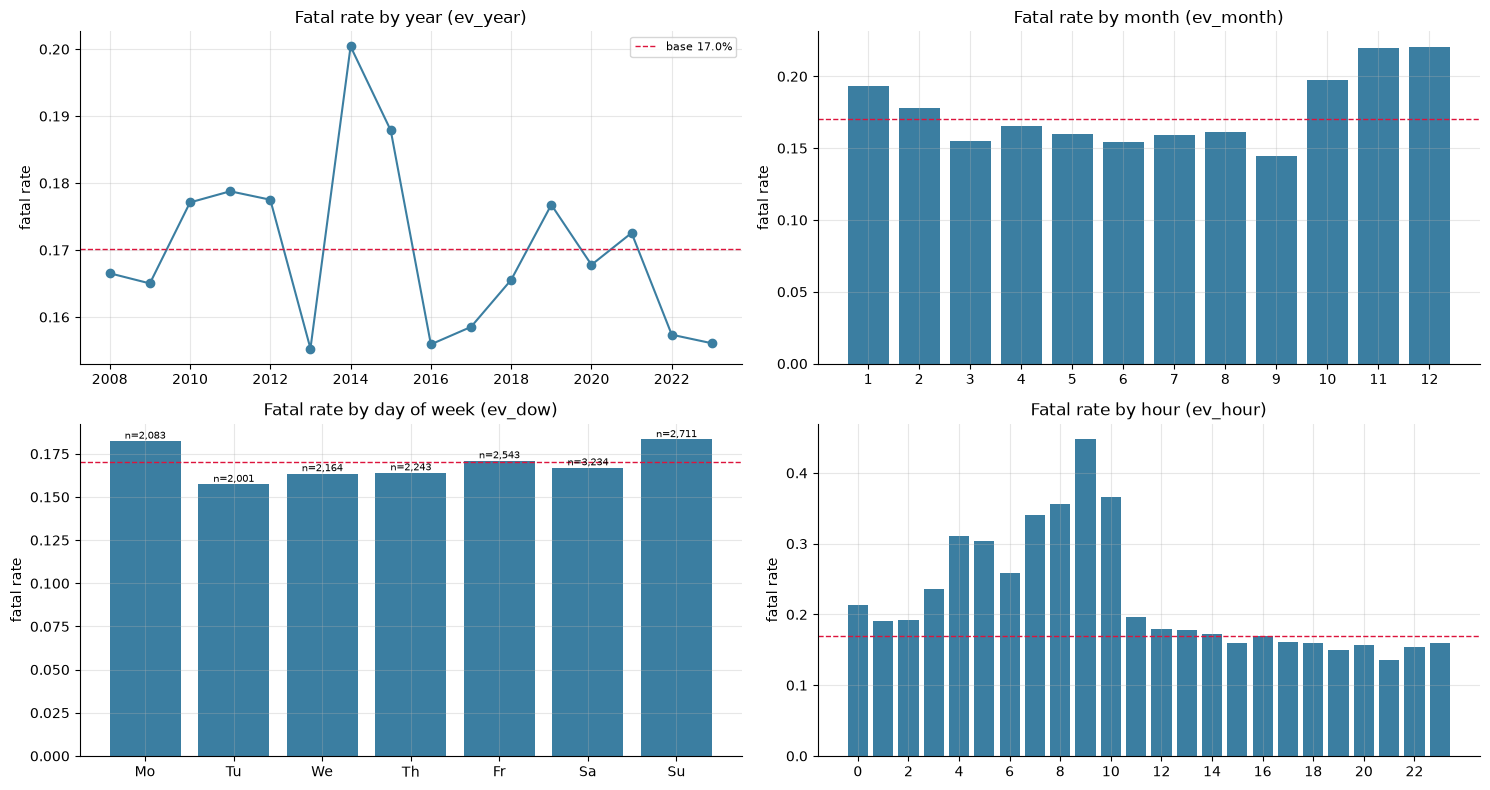

ev_year share (%) in learn vs predict (max abs diff: 0.97 pp):
ev_year    2008  2009  2010  2011  2012  2013  2014  2015  2016  2017  2018  2019  2020  2021  2022  2023
learn_%     7.5  7.14  7.05  7.21  6.97  5.95  5.88  6.02  6.12  5.91  6.15  5.93  5.23  5.67  5.80  5.47
predict_%   7.7  7.33  6.08  6.95  7.42  5.94  6.15  5.72  5.89  6.69  6.17  6.05  5.18  5.18  5.75  5.80

Rows with missing ev_hour: 19 · fatal rate: 0.684


In [4]:
dow_order = ["Mo", "Tu", "We", "Th", "Fr", "Sa", "Su"]

fig, ax = plt.subplots(2, 2, figsize=(15, 8))

# Year
yr = T.groupby("ev_year")["fatal"].agg(rate="mean", n="size")
ax[0, 0].plot(yr.index, yr["rate"], marker="o", color="#3b7ea1")
ax[0, 0].axhline(BASE, color="crimson", ls="--", lw=1, label=f"base {BASE:.1%}")
ax[0, 0].set_title("Fatal rate by year (ev_year)"); ax[0, 0].set_ylabel("fatal rate"); ax[0, 0].legend(fontsize=8)

# Month
mo = T.groupby("ev_month")["fatal"].agg(rate="mean", n="size")
ax[0, 1].bar(mo.index, mo["rate"], color="#3b7ea1")
ax[0, 1].axhline(BASE, color="crimson", ls="--", lw=1)
ax[0, 1].set_xticks(range(1, 13)); ax[0, 1].set_title("Fatal rate by month (ev_month)"); ax[0, 1].set_ylabel("fatal rate")

# Day of week
dw = T.groupby("ev_dow")["fatal"].agg(rate="mean", n="size").loc[dow_order]
ax[1, 0].bar(dw.index, dw["rate"], color="#3b7ea1")
ax[1, 0].axhline(BASE, color="crimson", ls="--", lw=1)
for i, (r, n) in enumerate(zip(dw["rate"], dw["n"])):
    ax[1, 0].text(i, r, f"n={n:,}", ha="center", va="bottom", fontsize=7)
ax[1, 0].set_title("Fatal rate by day of week (ev_dow)"); ax[1, 0].set_ylabel("fatal rate")

# Hour
hr = T.groupby("ev_hour")["fatal"].agg(rate="mean", n="size")
ax[1, 1].bar(hr.index, hr["rate"], color="#3b7ea1")
ax[1, 1].axhline(BASE, color="crimson", ls="--", lw=1)
ax[1, 1].set_xticks(range(0, 24, 2)); ax[1, 1].set_title("Fatal rate by hour (ev_hour)"); ax[1, 1].set_ylabel("fatal rate")

plt.tight_layout(); plt.show()

# Check ev_year stability between learn and predict
yr_cmp = pd.DataFrame({
    "learn_%": (learn["ev_year"].value_counts(normalize=True) * 100).round(2),
    "predict_%": (predict["ev_year"].value_counts(normalize=True) * 100).round(2),
}).sort_index()
print("ev_year share (%) in learn vs predict (max abs diff:",
      f"{(yr_cmp['learn_%'] - yr_cmp['predict_%']).abs().max():.2f} pp):")
print(yr_cmp.T)
print("\nRows with missing ev_hour:", T["ev_hour"].isna().sum(),
      "· fatal rate:", round(T.loc[T["ev_hour"].isna(), "fatal"].mean(), 3))

**Interpretation.**
- **`ev_year`:** fatal rate is fairly stable across 2008–2023 (15.5%–20.0%, no strong trend). Importantly, **`learn` and `predict` have almost identical year distributions** (max difference < 1 percentage point), confirming a random (non-temporal) split across 2008–2023.
- **`ev_month`:** clear seasonal pattern. Summer months (Jun–Sep) have the highest accident volume (~1,700–2,160/month) but lower fatal rates (**14.5%–16.2%**), whereas late autumn and winter (Oct–Jan) have fewer accidents (~880–1,350/month) and noticeably higher fatal rates (**19.3%–22.0%**, peaking in Nov–Dec), likely tied to worse weather and shorter daylight.
- **`ev_dow`:** weak signal. Volume peaks on weekends (Saturday 3,234, Sunday 2,711), while fatal rate barely moves (15.7% on Tuesday to 18.3% on Sunday).
- **`ev_hour`:** strong signal — **and a major surprise**. Fatal rate surges to **26%–45% between hours 04 and 10** (where volume is lowest: 38–145 rows/hour) and stays around **14%–17% between hours 14 and 23** (where volume peaks at ~1,200–1,500/hour). That is inverted relative to US local daytime, which points directly to a timezone issue (checked next). Also, the 19 rows with missing `ev_hour` have a **68.4%** fatal rate.

**→ NB1:** encode `ev_month` and `ev_hour` cyclically (`sin`/`cos`) or let tree models split on them; add an `ev_hour_missing` flag; `ev_year` and `ev_dow` are weak standalone features (keep or test in feature selection).

## Part 2 · 3. Light vs time: does `light_cond` agree with `ev_hour`?

**What we do:** check `light_cond` against `fatal` and cross-tabulate `ev_hour` against `light_cond` to test whether `ev_hour` is truly local time as stated in `data_dictionary.md`.

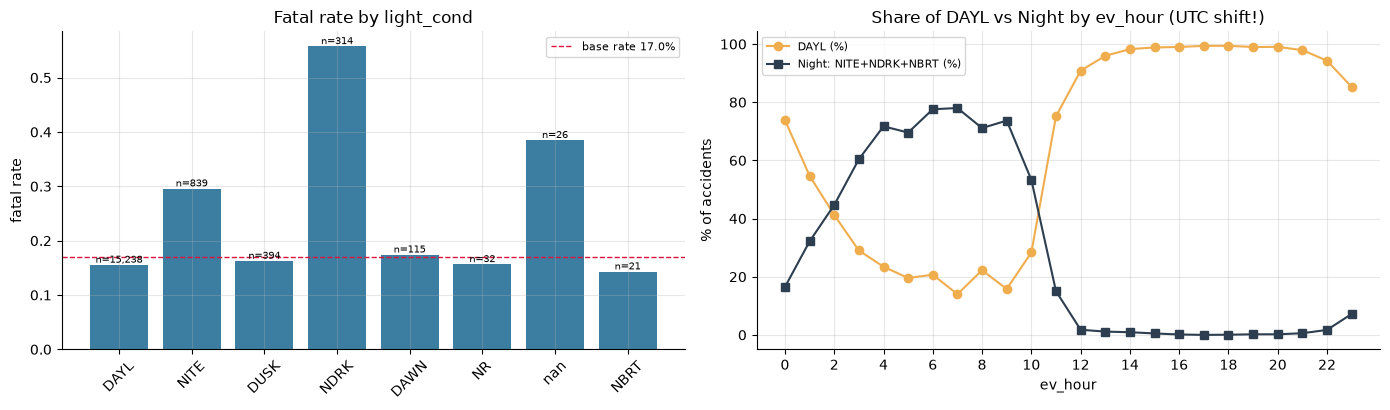

DAWN peak hours: {12: 22, 11: 17, 13: 15, 10: 8}
DUSK peak hours: {23: 85, 0: 75, 1: 72, 2: 48}


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
plot_cat_vs_target(T, "light_cond", min_n=1, ax=ax[0], title="Fatal rate by light_cond")

ct = pd.crosstab(T["ev_hour"].dropna().astype(int), T["light_cond"].fillna("NaN"))
night_cols = [c for c in ["NITE", "NDRK", "NBRT"] if c in ct.columns]
day_share = ct["DAYL"] / ct.sum(axis=1) * 100
night_share = ct[night_cols].sum(axis=1) / ct.sum(axis=1) * 100

ax[1].plot(ct.index, day_share, marker="o", label="DAYL (%)", color="#f0ad4e")
ax[1].plot(ct.index, night_share, marker="s", label="Night: NITE+NDRK+NBRT (%)", color="#2c3e50")
ax[1].set_xticks(range(0, 24, 2)); ax[1].set_xlabel("ev_hour"); ax[1].set_ylabel("% of accidents")
ax[1].set_title("Share of DAYL vs Night by ev_hour (UTC shift!)"); ax[1].legend(fontsize=8)

plt.tight_layout(); plt.show()

print("DAWN peak hours:", ct["DAWN"].sort_values(ascending=False).head(4).to_dict())
print("DUSK peak hours:", ct["DUSK"].sort_values(ascending=False).head(4).to_dict())

**Interpretation.**
- **`light_cond` is a very strong predictor:** `DAYL` (90% of rows) has a **15.5%** fatal rate, `NITE` jumps to **29.6%**, and **`NDRK` (night, dark) reaches 55.7%** (more than 3× the base rate). Missing `light_cond` (26 rows) is also high at **38.5%**.
- **`ev_hour` does NOT match US local time — it is in UTC** (shifted ~5–8 hours ahead of US time zones, contradicting `data_dictionary.md`):
  - `DAYL` accounts for **94%–99%** of accidents between `ev_hour` 13 and 22 (US daytime in UTC).
  - `DAWN` peaks at hours **11–13** (~6–8 AM US local).
  - `DUSK` peaks at hours **23–01** (~6–8 PM US local).
  - Night (`NITE`/`NDRK`/`NBRT`) dominates between hours **03 and 10**, explaining why those hours had the 30%–45% fatal rates in section 2.
- Because the US spans multiple time zones (UTC-5 to UTC-8, plus Alaska/Hawaii) and daylight saving time changes through the year, `ev_hour` is a noisy proxy for actual darkness, whereas `light_cond` measures it directly.

**→ NB1:** treat `light_cond` as a key feature (keep `NDRK` separate from `NITE`/`NBRT` — do not collapse all night codes into one, since `NDRK` is 55.7% vs `NITE` 29.6%); keep `NaN`/`NR` explicit. For `ev_hour`, remember it is UTC (cyclic encoding still works fine for models, and `ev_hour` + `light_cond` together capture both time-of-day traffic patterns and true lighting).

## Part 2 · 4. Distance to airport: is `apt_dist = 0` real or a missing-value code?

**What we do:** 77.3% of `learn` (and 77.6% of `predict`) have `apt_dist == 0`. We test whether zero means "at the airport" or "missing" by crossing `apt_dist == 0` with `phase`, `apt_elev.isna()` and `fatal`, and by checking extreme values.

apt_dist == 0: 77.3% in learn · 77.6% in predict
apt_dist > 100 in learn: 70 · max: 7208 · max in predict: 7654

4 quadrants (apt_dist == 0 x apt_elev missing):
                              group  rate    n
 dist=0 & elev present (on-airport) 0.085 7533
   dist=0 & elev NaN (missing code) 0.217 5586
dist>0 & elev present (off-airport) 0.269 3734
                  dist>0 & elev NaN 0.246  126

% of apt_dist == 0 by top flight phases:
               pct_zero     n
phase                        
Landing            88.7  5435
Enroute            75.7  2751
Maneuvering        79.3  2243
Takeoff            81.8  2027
Approach           55.0  1925
Initial climb      57.0  1716
Taxi               87.1   394
Standing           90.1   202


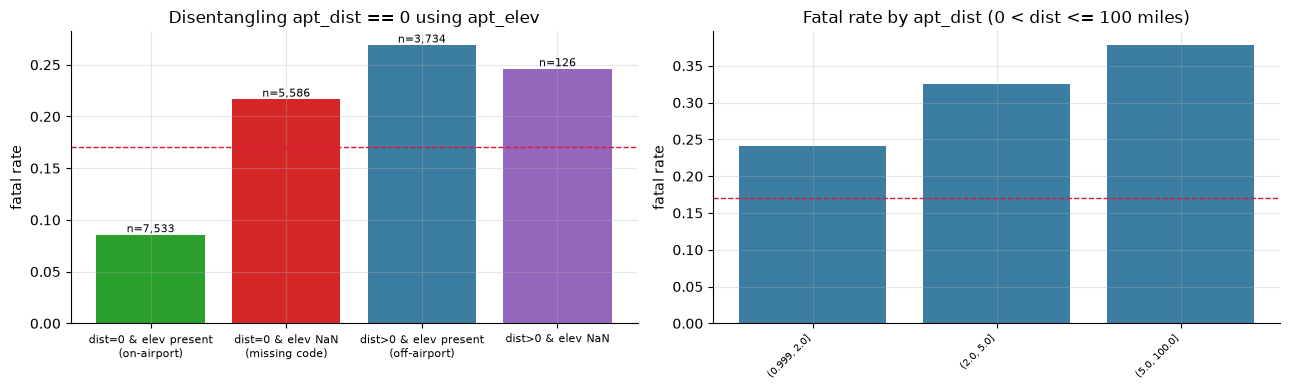

In [6]:
print(f"apt_dist == 0: {(T.apt_dist == 0).mean():.1%} in learn · {(predict.apt_dist == 0).mean():.1%} in predict")
print("apt_dist > 100 in learn:", (T.apt_dist > 100).sum(), "· max:", T.apt_dist.max(),
      "· max in predict:", predict.apt_dist.max())

# 4-way breakdown: apt_dist == 0 vs apt_elev missing
g1 = T[(T["apt_dist"] == 0) & (T["apt_elev"].notna())]
g2 = T[(T["apt_dist"] == 0) & (T["apt_elev"].isna())]
g3 = T[(T["apt_dist"] > 0) & (T["apt_elev"].notna())]
g4 = T[(T["apt_dist"] > 0) & (T["apt_elev"].isna())]

groups = [g1, g2, g3, g4]
labels = ["dist=0 & elev present\n(on-airport)", "dist=0 & elev NaN\n(missing code)",
          "dist>0 & elev present\n(off-airport)", "dist>0 & elev NaN"]
rates = [g["fatal"].mean() for g in groups]
ns = [len(g) for g in groups]

q4 = pd.DataFrame({"group": [l.replace("\n", " ") for l in labels],
                   "rate": [round(r, 3) for r in rates], "n": ns})
print("\n4 quadrants (apt_dist == 0 x apt_elev missing):")
print(q4.to_string(index=False))

# Phase breakdown for apt_dist == 0
ph = (T.groupby("phase")["apt_dist"]
        .agg(pct_zero=lambda s: (s == 0).mean() * 100, n="size")
        .sort_values("n", ascending=False).head(8))
print("\n% of apt_dist == 0 by top flight phases:")
print(ph.round(1))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(range(4), rates, color=["#2ca02c", "#d62728", "#3b7ea1", "#9467bd"])
ax[0].axhline(BASE, color="crimson", ls="--", lw=1)
ax[0].set_xticks(range(4)); ax[0].set_xticklabels(labels, fontsize=8)
for i, (r, n) in enumerate(zip(rates, ns)):
    ax[0].text(i, r, f"n={n:,}", ha="center", va="bottom", fontsize=8)
ax[0].set_ylabel("fatal rate"); ax[0].set_title("Disentangling apt_dist == 0 using apt_elev")

plot_num_vs_target(T[(T.apt_dist > 0) & (T.apt_dist <= 100)], "apt_dist", q=6, ax=ax[1],
                   title="Fatal rate by apt_dist (0 < dist <= 100 miles)")
plt.tight_layout(); plt.show()

**Interpretation.**
- **`apt_dist = 0` is BOTH real AND a missing-value code — mixed together:**
  - **Real on-airport accidents (`apt_dist == 0` & `apt_elev` present, n = 7,533):** fatal rate is only **8.5%** (half the base rate). Consistent with `Landing` (88.7% zero), `Takeoff` (81.8%) and `Taxi` (87.1%).
  - **Disguised missing values (`apt_dist == 0` & `apt_elev` is `NaN`, n = 5,586):** fatal rate jumps to **21.7%**. Notably, **75.7% of `Enroute`** and **79.3% of `Maneuvering`** accidents have `apt_dist == 0`, and **97.8%** of all rows with missing `apt_elev` have `apt_dist == 0`. When no airport was linked to the record, `apt_dist` was stored as `0` instead of `NaN`.
  - **Known off-airport accidents (`apt_dist > 0`, n = 3,860):** fatal rate is **26.8%**.
- **Extreme outliers:** 70 rows in `learn` (and 18 in `predict`) have `apt_dist > 100` statute miles, going up to **7,208** (and 7,654 in `predict`) — physically impossible in the USA and clearly coordinate/entry errors.

**→ NB1:** (1) separate true zeros from disguised missing values by setting `apt_dist = NaN` when `apt_dist == 0` and `apt_elev` is `NaN`, or create an explicit 3-level categorical feature (`on_airport`, `off_airport`, `no_airport_recorded`); (2) cap/winsorise or set `apt_dist > 100` (or > 50) to `NaN` and consider `log1p(apt_dist)`.

## Part 2 · 5. Airport elevation: why is `apt_elev` missing, and is it related to `fatal`?

**What we do:** check `apt_elev` missingness across `ev_year` and `phase`, test its relationship with `fatal`, and inspect impossible/extreme elevation values.

**Interpretation.**
- **`apt_dist = 0` is BOTH real AND a missing-value code — mixed together:**
  - **Real on-airport accidents (`apt_dist == 0` & `apt_elev` present, n = 7,533):** fatal rate is only **8.5%** (half the base rate). Consistent with `Landing` (88.7% zero), `Takeoff` (81.8%) and `Taxi` (87.1%).
  - **Disguised missing values (`apt_dist == 0` & `apt_elev` is `NaN`, n = 5,586):** fatal rate jumps to **21.7%**. Notably, **75.7% of `Enroute`** and **79.3% of `Maneuvering`** accidents have `apt_dist == 0`, and **97.8%** of all rows with missing `apt_elev` have `apt_dist == 0`. When no airport was linked to the record, `apt_dist` was stored as `0` instead of `NaN`.
  - **Known off-airport accidents (`apt_dist > 0`, n = 3,860):** fatal rate is **26.8%**.
- **Extreme outliers:** 70 rows in `learn` (and 18 in `predict`) have `apt_dist > 100` statute miles, going up to **7,208** (and 7,654 in `predict`) — physically impossible in the USA and clearly coordinate/entry errors.

**→ NB1:** (1) separate true zeros from disguised missing values by setting `apt_dist = NaN` when `apt_dist == 0` and `apt_elev` is `NaN`, or create an explicit 3-level categorical feature (`on_airport`, `off_airport`, `no_airport_recorded`); (2) cap/winsorise or set `apt_dist > 100` (or > 50) to `NaN` and consider `log1p(apt_dist)`.

apt_elev summary:
{'count': 11267.0, 'mean': 1350.5, 'std': 1782.1, 'min': -224.0, '25%': 158.0, '50%': 697.0, '75%': 1457.0, 'max': 33333.0}
apt_elev < 0: 18 · min: -224.0 · > 10,000 ft: 1 · max: 33333.0

Fatal rate, apt_elev missing vs present:
           rate      n
apt_elev              
False     0.146  11267
True      0.217   5712


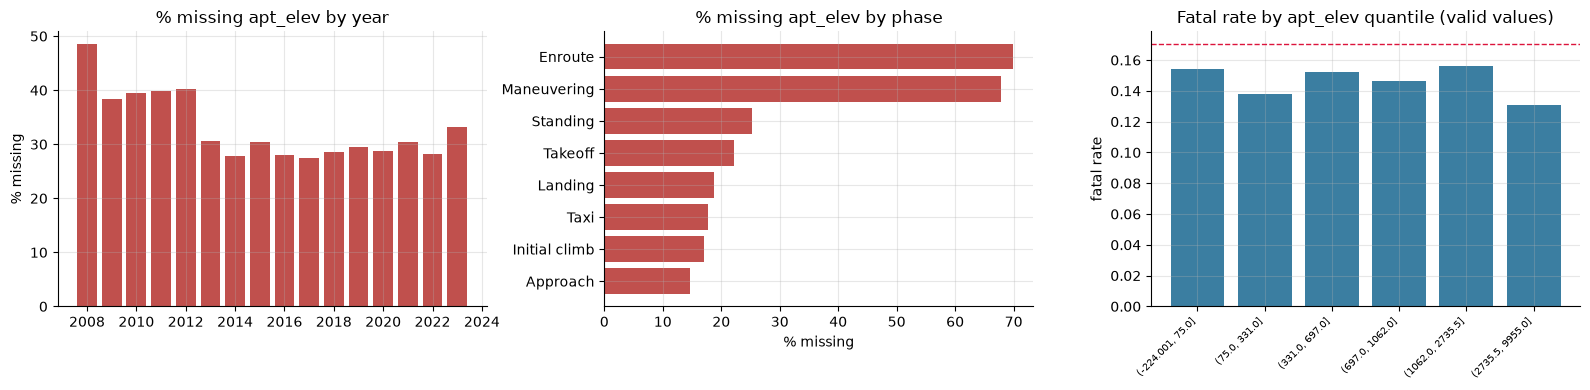

In [7]:
print("apt_elev summary:")
print(T["apt_elev"].describe().round(1).to_dict())
print("apt_elev < 0:", (T.apt_elev < 0).sum(), "· min:", T.apt_elev.min(),
      "· > 10,000 ft:", (T.apt_elev > 10000).sum(), "· max:", T.apt_elev.max())
print("\nFatal rate, apt_elev missing vs present:")
print(T.groupby(T["apt_elev"].isna())["fatal"].agg(rate="mean", n="size").round(3))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))

# Missingness by year
miss_yr = T.groupby("ev_year")["apt_elev"].apply(lambda s: s.isna().mean() * 100)
ax[0].bar(miss_yr.index, miss_yr.values, color="#c0504d")
ax[0].set_title("% missing apt_elev by year"); ax[0].set_ylabel("% missing")

# Missingness by top flight phases
top_ph = T["phase"].value_counts().head(8).index
miss_ph = T[T["phase"].isin(top_ph)].groupby("phase")["apt_elev"].apply(lambda s: s.isna().mean() * 100).sort_values()
ax[1].barh(miss_ph.index, miss_ph.values, color="#c0504d")
ax[1].set_title("% missing apt_elev by phase"); ax[1].set_xlabel("% missing")

# Fatal rate by valid apt_elev quantile
plot_num_vs_target(T[T["apt_elev"].between(-300, 10000)], "apt_elev", q=6, ax=ax[2],
                   title="Fatal rate by apt_elev quantile (valid values)")

plt.tight_layout(); plt.show()

**Interpretation.**
- **Why is `apt_elev` missing (33.6%)?** Primarily because **the accident did not happen at/near a registered airport**: missingness is **69.9% in `Enroute`** and **67.8% in `Maneuvering`**, versus only **15%–22%** in `Approach`, `Initial climb`, `Landing` and `Takeoff`. There is also a mild reporting-era effect (38%–49% missing in 2008–2012 vs ~28%–33% from 2013 onward).
- **Strong link to `fatal`:** rows with missing `apt_elev` have a **21.7%** fatal rate versus **14.6%** when present. Missingness is **not random (MNAR/MAR)** — it is a strong proxy for off-airport accidents.
- **Data quality:** 18 rows have slightly negative elevations down to `-224` ft, which are **real** (e.g., airports below sea level in California such as Death Valley / Salton Sea). However, `max = 33,333` ft (1 row) is impossible (the highest US airport is < 10,000 ft) and is a typo/sentinel value.

**→ NB1:** **definitely add an `apt_elev_missing` binary indicator** before imputing (it carries strong signal); replace `apt_elev > 10,000` ft with `NaN`; keep small negative values (down to ~`-300` ft) as valid.

## Part 2 · 6. Findings and decisions for NB1 (input for Person 1's final table)

In [8]:
findings_p2 = pd.DataFrame([
    ("ev_year", "Fatal rate stable (15.5%-20.0%); identical year distribution in learn and predict (random split)", "Weak standalone feature; safe to use year-related missingness flags (e.g. acft_year)"),
    ("ev_month", "Seasonal pattern: higher fatal rate in Oct-Jan (19%-22%) vs Jun-Sep (15%-16%)", "Keep; consider cyclical sin/cos encoding or winter indicator"),
    ("ev_dow", "Higher volume on weekends, very weak fatal-rate variation (15.7%-18.3%)", "Low priority; test in feature selection"),
    ("ev_hour", "Stored in UTC, NOT local time (DAYL peaks at 13-22h, Night at 03-10h); 19 NaNs have 68.4% fatal rate", "Keep with cyclic encoding; add ev_hour_missing flag; do not assume 0-23 is local time"),
    ("light_cond", "Strong predictor: DAYL 15.5%, NITE 29.6%, NDRK 55.7%, NaN 38.5%", "Keep NDRK separate from NITE/NBRT; keep NaN/NR as explicit category"),
    ("apt_dist", "77.3% zeros are a mix: on-airport (elev present, 8.5% fatal) vs disguised missing (elev NaN, 21.7% fatal); 70 outliers > 100 mi (up to 7,208)", "Convert dist==0 & elev NaN -> NaN (or build 3-way airport-status feature); cap/NaN values > 100 mi; consider log1p"),
    ("apt_elev", "33.6% missing, mainly off-airport (Enroute 70%, Maneuvering 68%); missing = 21.7% fatal vs 14.6% present; 1 typo at 33,333 ft (-224 ft is valid)", "Add apt_elev_missing indicator before imputation; set > 10,000 ft to NaN; keep negative values"),
], columns=["Column(s)", "Finding", "Decision / question for NB1"])

pd.set_option("display.max_colwidth", 140)
findings_p2

,Column(s),Finding,Decision / question for NB1
0,ev_year,Fatal rate stable (15.5%-20.0%); identical year distribution in learn and predict (random split),Weak standalone feature; safe to use year-related missingness flags (e.g. acft_year)
1,ev_month,Seasonal pattern: higher fatal rate in Oct-Jan (19%-22%) vs Jun-Sep (15%-16%),Keep; consider cyclical sin/cos encoding or winter indicator
2,ev_dow,"Higher volume on weekends, very weak fatal-rate variation (15.7%-18.3%)",Low priority; test in feature selection
3,ev_hour,"Stored in UTC, NOT local time (DAYL peaks at 13-22h, Night at 03-10h); 19 NaNs have 68.4% fatal rate",Keep with cyclic encoding; add ev_hour_missing flag; do not assume 0-23 is local time
4,light_cond,"Strong predictor: DAYL 15.5%, NITE 29.6%, NDRK 55.7%, NaN 38.5%",Keep NDRK separate from NITE/NBRT; keep NaN/NR as explicit category
5,apt_dist,"77.3% zeros are a mix: on-airport (elev present, 8.5% fatal) vs disguised missing (elev NaN, 21.7% fatal); 70 outliers > 100 mi (up to 7...",Convert dist==0 & elev NaN -> NaN (or build 3-way airport-status feature); cap/NaN values > 100 mi; consider log1p
6,apt_elev,"33.6% missing, mainly off-airport (Enroute 70%, Maneuvering 68%); missing = 21.7% fatal vs 14.6% present; 1 typo at 33,333 ft (-224 ft i...","Add apt_elev_missing indicator before imputation; set > 10,000 ft to NaN; keep negative values"


# ━━━━━━━━━━ PART 4 · Aircraft and engine (Person 4) ━━━━━━━━━━

Columns covered (11): `acft_category`, `homebuilt`, `fixed_retractable`, `acft_make`, `ifr_equipped_cert`, `num_eng`, `total_seats`, `acft_year`, `eng_type`, `carb_fuel_injection`, `eng_power`.

NB0 does not change the data and does not train models. When a cleaning step is needed just to *look* at something (for example upper-casing a category), it is done on a throw-away copy, and the real cleaning is listed as a decision for NB1 at the end of this part.

In [3]:
# Only needed by Part 4
import re

GROUP = ["acft_category", "homebuilt", "fixed_retractable", "acft_make", "ifr_equipped_cert",
         "num_eng", "total_seats", "acft_year", "eng_type", "carb_fuel_injection", "eng_power"]

## Part 4 · 1. Overview of the group

**What we do:** data types, missing values and cardinality of the 11 columns, in `learn` and in `predict`.

In [4]:
ov = pd.DataFrame({
    "dtype": learn[GROUP].dtypes.astype(str),
    "missing_learn_%": (learn[GROUP].isna().mean() * 100).round(1),
    "missing_predict_%": (predict[GROUP].isna().mean() * 100).round(1),
    "n_unique": learn[GROUP].nunique(),
})
ov

,dtype,missing_learn_%,missing_predict_%,n_unique
acft_category,str,0.0,0.0,19
homebuilt,str,0.0,0.0,4
fixed_retractable,str,0.0,0.0,2
acft_make,str,0.0,0.0,2914
ifr_equipped_cert,int64,0.0,0.0,2
num_eng,float64,2.9,2.8,7
total_seats,float64,7.1,7.2,135
acft_year,float64,40.1,39.8,102
eng_type,str,3.5,3.7,11
carb_fuel_injection,str,21.2,21.5,2


**Interpretation.**
- Missingness is very uneven: `acft_year` (40%), `carb_fuel_injection` (21%), `eng_power` (11%), `total_seats` (7%), `eng_type` (3.5%), `num_eng` (2.9%). The other six columns are complete. `learn` and `predict` have similar missing rates, which is good (no shift in how the data was collected).
- `acft_make` has 2,914 distinct values: it is a free-text field, not a real category (section 3).
- `num_eng`, `total_seats`, `acft_year` and `eng_power` are floats only because of the NaNs.

**→ NB1:** missing values need an explicit strategy per column (imputation and/or a missing indicator). Section 6 shows that the 40% in `acft_year` is not random.

## Part 4 · 2. Inconsistent case: `acft_category` and `homebuilt`

**What we do:** the brief warns that `AIR`/`air`, `HELI`/`heli` and `Y`/`y` coexist. We check how widespread it is (also in `predict`) and whether the lowercase rows mean something different. We work on a copy `A`; `learn` is untouched.

In [ ]:
for col in ["acft_category", "homebuilt"]:
    print(pd.concat({"learn": learn[col].value_counts(), "predict": predict[col].value_counts()}, axis=1)
            .fillna(0).astype(int).sort_values("learn", ascending=False), "\n")

print("rows with lowercase acft_category:", (learn.acft_category.str.islower()).sum(),
      f"({learn.acft_category.str.islower().mean():.1%})")
print("rows with lowercase homebuilt:    ", (learn.homebuilt.str.islower()).sum(),
      f"({learn.homebuilt.str.islower().mean():.1%})")

In [ ]:
A = learn.copy()                                  # throw-away copy for analysis only
A["acft_category_u"] = A["acft_category"].str.upper()
A["homebuilt_u"] = A["homebuilt"].str.upper()
A["was_lower"] = A["acft_category"].str.islower()

print("Fatal rate: uppercase vs lowercase spelling (same category?)")
print(A.groupby("was_lower")["fatal"].agg(["mean", "size"]).round(3), "\n")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
plot_cat_vs_target(A, "acft_category_u", min_n=15, ax=ax[0], title="Fatal rate by acft_category (case unified)")
plot_cat_vs_target(A, "homebuilt_u", min_n=15, ax=ax[1], title="Fatal rate by homebuilt (case unified)")
plt.tight_layout(); plt.show()

**Interpretation.**
- About a quarter of the rows are lowercase (`air` 3,655 vs `AIR` 10,899, `n` 3,707 vs `N` 10,894...) and `predict` has the same pattern, so a model fed the raw strings would treat `AIR` and `air` as different levels.
- Lowercase is **noise in the spelling**, not information: the fatal rate is about the same in both groups. After unifying, the categories behave sensibly: airplanes and helicopters are close to the base rate (17%/16%), weight-shift (`WSFT`) is much riskier (36%), balloons and powered parachutes are safer (7–10%). Homebuilt aircraft are more fatal (23% vs 16%).
- Several categories are tiny (`PLFT` 2, `RCKT` 1, `BLIM` 1, `ULTR` 17): their rates are meaningless.

**→ NB1:** upper-case both columns (and apply the same function to `predict`); group categories with fewer than about 30 rows into `OTHER`.

## Part 4 · 3. Aircraft make: `acft_make`

**What we do:** study the cardinality, the spelling variants and the rare makes. Normalisation here (upper case, remove punctuation and company suffixes) is only used to *measure* how much of the 2,914 distinct values are really the same make.

In [ ]:
def norm_make(s):
    s = str(s).upper()
    s = re.sub(r"[^A-Z0-9 ]", "", s)
    s = re.sub(r"\b(INC|CORP|CORPORATION|CO|COMPANY|LLC|LTD|THE)\b", "", s)
    return re.sub(r"\s+", " ", s).strip()

A["make_n"] = A["acft_make"].map(norm_make)
P = predict.copy(); P["make_n"] = P["acft_make"].map(norm_make)

vc = A["make_n"].value_counts()
print(f"distinct raw values: {learn.acft_make.nunique():,} · after light normalisation: {A.make_n.nunique():,}")
print(f"makes with >=100 rows: {(vc >= 100).sum()} · >=30 rows: {(vc >= 30).sum()} · <=5 rows: {(vc <= 5).sum():,} · exactly 1 row: {(vc == 1).sum():,}")
print(f"share of rows covered by top 10 / 50 / 200 makes: "
      f"{vc.head(10).sum()/len(A):.0%} / {vc.head(50).sum()/len(A):.0%} / {vc.head(200).sum()/len(A):.0%}")
print(f"share of rows that belong to makes with <=5 rows: {vc[vc <= 5].sum()/len(A):.1%}")
print(f"share of predict rows whose (normalised) make never appears in learn: {(~P.make_n.isin(A.make_n)).mean():.1%}")
print("\nSpelling variants, e.g. ROBINSON and CESSNA:")
print(learn[learn.acft_make.str.upper().str.contains("ROBINSON HELI|^ROBINSON$")].acft_make.value_counts().head(6).to_string())
print(learn[learn.acft_make.str.upper().str.contains("CESSNA")].acft_make.value_counts().head(5).to_string())

In [ ]:
top = vc[vc >= 100].index
g = (A[A.make_n.isin(top)].groupby("make_n")["fatal"].agg(rate="mean", n="size").sort_values("rate"))
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].barh(g.index, g["rate"], color="#3b7ea1"); ax[0].axvline(BASE, color="crimson", ls="--")
for i, (r, n) in enumerate(zip(g["rate"], g["n"])): ax[0].text(r, i, f" n={n}", va="center", fontsize=7)
ax[0].set_title("Fatal rate for the 17 makes with >=100 rows"); ax[0].set_xlabel("fatal rate")

rank = np.arange(1, len(vc) + 1)
ax[1].plot(rank, vc.values.cumsum() / vc.sum()); ax[1].set_xscale("log")
ax[1].set_title("Cumulative share of rows covered by the top-k makes"); ax[1].set_xlabel("k (log)")
plt.tight_layout(); plt.show()

rare = A["make_n"].map(vc) <= 5
print("fatal rate, makes with <=5 rows vs the rest:", round(A[rare].fatal.mean(), 3), "vs", round(A[~rare].fatal.mean(), 3))

**Interpretation.**
- Light normalisation only reduces 2,914 values to ~2,800 and merges the big duplicates (`ROBINSON` vs `ROBINSON HELICOPTER`, `CESSNA` vs `CESSNA AIRCRAFT CO`). The remaining ones are mostly one-off names (homebuilders, individuals, old manufacturers): ~2,300 makes appear only once.
- It is a long-tail variable: only 17 makes have ≥ 100 rows (top 10 ≈ 56% of the rows, top 50 ≈ 71%) while ~19% of the rows belong to makes with ≤ 5 rows.
- About **13% of `predict` rows have a make that never appears in `learn`**, so the model will have to deal with unseen categories. A plain one-hot over all makes would be huge and mostly useless.
- There *is* signal in the big makes: Boeing 3%, Schweizer 7%, Maule 8% versus Cirrus 33%, Vans 29%, Mooney 29%, Beech 27% (base rate 17%). Rare makes are riskier than average (21% vs 16%), probably because they are homebuilt/experimental or old aircraft.

**→ NB1:** (1) normalise the text; (2) keep the top ~30–50 makes and group the rest as `OTHER` (or use frequency encoding / target encoding **inside** the cross-validation to avoid leakage); (3) add a `make_is_rare` flag; (4) make sure the encoding handles makes unseen in `learn`.

## Part 4 · 4. Other categorical columns versus the target

**What we do:** `fixed_retractable`, `ifr_equipped_cert`, `num_eng`, `eng_type` and `carb_fuel_injection` against `fatal`. Missing values are kept as their own group (`dropna=False`) so we can see if missing is informative.

In [ ]:
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
plot_cat_vs_target(A, "fixed_retractable", min_n=1, ax=ax[0, 0])
plot_cat_vs_target(A, "ifr_equipped_cert", min_n=1, ax=ax[0, 1])
plot_cat_vs_target(A, "num_eng", min_n=1, ax=ax[0, 2])
plot_cat_vs_target(A, "eng_type", min_n=1, ax=ax[1, 0])
plot_cat_vs_target(A, "carb_fuel_injection", min_n=1, ax=ax[1, 1])
ax[1, 2].axis("off")
plt.tight_layout(); plt.show()

In [ ]:
print("eng_type vs carb_fuel_injection (counts):")
print(pd.crosstab(A.eng_type.fillna("NaN"), A.carb_fuel_injection.fillna("NaN")))
print("\nnum_eng == 0 by aircraft category:")
print(A[A.num_eng == 0].acft_category_u.value_counts())

**Interpretation.**
- **Retractable gear** is clearly riskier (24% vs 15%). Faster, more complex aircraft: a strong, simple feature.
- `num_eng`: twins (2) are riskier (22%) than singles (16.5%). `num_eng = 0` (243 rows, 7% fatal) are gliders and balloons, so it is a valid value, not an error. 3, 4, 6, 8 engines are almost never seen (≤ 17 rows).
- `eng_type`: `REC` (piston) is 83% of the data. `TP` turboprop has the highest rate (23%); `TF` turbofan is the lowest (9%, large airliners). Rare codes (`HR`, `GTFN`, `LR`, `ELEC`, `NONE`, `UNK`) have ≤ 23 rows.
- `carb_fuel_injection`: fuel-injected is riskier (22% vs 15%). But `NaN` is **structural**: it only makes sense for piston engines, and it is missing for 73–84% of turbine engines and 100% of electric/no-engine. That is "not applicable", not "unknown". Within `REC` it is missing for only 9%.
- `ifr_equipped_cert` has a weak effect (19% vs 17%).

**→ NB1:** keep `NaN` in `carb_fuel_injection` as an explicit category (`NOT_APPLICABLE`/`UNKNOWN`), group rare `eng_type` codes, cap `num_eng` at 3+ (or treat as category). Question: `retractable`, `eng_type` and `num_eng` are probably correlated (powerful complex aircraft): check redundancy during feature selection.

## Part 4 · 5. The column whose unit changes: `eng_power`

**What we do:** the dictionary says `eng_power` is horsepower for piston and turboprop engines and pounds of thrust for jets. We plot it split by `eng_type` and look at zeros and extremes.

In [ ]:
order = ["ELEC", "REC", "TP", "TS", "TJ", "TF"]
print(A.groupby("eng_type")["eng_power"].describe().round(0).loc[lambda d: d["count"] > 0])

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
data = [A.loc[(A.eng_type == t) & (A.eng_power > 0), "eng_power"] for t in order]
ax[0].boxplot(data, tick_labels=[f"{t}\n(n={len(d)})" for t, d in zip(order, data)], showfliers=True)
ax[0].set_yscale("log"); ax[0].set_title("eng_power by eng_type (log scale, zeros excluded)"); ax[0].set_ylabel("HP or lbs of thrust")
ax[1].hist(np.log10(A.loc[A.eng_power > 0, "eng_power"]), bins=60, color="#3b7ea1")
ax[1].set_title("log10(eng_power): mixture of units"); ax[1].set_xlabel("log10(eng_power)")
plt.tight_layout(); plt.show()

print("\neng_power == 0:", (A.eng_power == 0).sum(), "rows · by eng_type:")
print(A[A.eng_power == 0].eng_type.value_counts(dropna=False).head())
print("\nlowest power among jets (lbs of thrust should be in the thousands):")
print(A[A.eng_type.isin(["TF", "TJ"]) & (A.eng_power > 0)].eng_power.nsmallest(5).tolist())
print("piston (REC) engines above 1,500 HP:", ((A.eng_type == "REC") & (A.eng_power > 1500)).sum(), "→ mostly large vintage aircraft")
print("\nmissing eng_power by eng_type (share):")
print(A.eng_power.isna().groupby(A.eng_type.fillna("NaN")).mean().round(2).loc[lambda s: s > 0])

In [ ]:
# Does power matter inside each unit family? (fatal rate by quantile bin, piston only)
rec = A[(A.eng_type == "REC") & (A.eng_power > 0)]
plot_num_vs_target(rec, "eng_power", q=8, title="Piston engines only: fatal rate by eng_power bin (HP)")
plt.tight_layout(); plt.show()
print("Fatal rate by eng_type, power==0 vs >0 (piston):",
      A[A.eng_type == "REC"].groupby(A.eng_power.eq(0))["fatal"].mean().round(3).to_dict())

**Interpretation.**
- The unit problem is real and big: piston engines are around 100–300 (HP), turboprops ~750 HP, but turbofans have a median of ~8,900 and go up to 264,190 (lbs of thrust, with outliers that look like errors). The histogram in log scale is a mix of two populations. A single numeric `eng_power` makes a jet look 50× "more powerful" than a piston when it has nothing to do with it, and it would dominate any distance- or scale-based model (and the mean/std).
- `eng_power = 0` in 171 rows (147 of them piston): impossible, it is a missing-value code. A few jets have power < 1,000 (probably HP-style entries in the wrong unit).
- `eng_power` is missing together with `eng_type`: for rows where `eng_type` is `NaN` it is missing 95% of the time.
- Within piston engines, check the last plot: if the fatal rate changes across HP bins there is signal once the unit is homogeneous (this is the comparison that makes sense; mixing HP and lbs is not).

**→ NB1:** treat `eng_power = 0` as `NaN`; build `eng_power_hp` (piston/turboprop/turboshaft/electric) and `eng_thrust_lbs` (TF/TJ) as two separate features (or a log-transform *interacted* with engine family). Cap or winsorise extreme values. Question: impute power by median per `eng_type`, or only flag it?

## Part 4 · 6. Impossible values: `total_seats` and `acft_year`

**What we do:** look for values that cannot be true (`acft_year` after the accident year or absurdly old, odd seat counts) and understand why `acft_year` is missing 40% of the time.

In [ ]:
print("=== total_seats ===")
print("seats == 0:", (A.total_seats == 0).sum(), " seats > 100:", (A.total_seats > 100).sum(), " max:", A.total_seats.max())
print(A.total_seats.describe().round(1).to_dict())
print("\nseats > 100: category / operation / fatal rate")
big = A[A.total_seats > 100]
print(big.acft_category_u.value_counts().to_dict(), big.far_part.value_counts().head(3).to_dict(), "fatal:", round(big.fatal.mean(), 3))
print("odd seat counts (3,5,7,9) vs even (2,4,6,8):", A.total_seats.isin([3, 5, 7, 9]).sum(), "vs", A.total_seats.isin([2, 4, 6, 8]).sum())
print("seats, median by category:", A.groupby("acft_category_u").total_seats.median().to_dict())

print("\n=== acft_year ===")
y = A["acft_year"]
print("acft_year == 0:", (y == 0).sum(), "· < 1900 (and > 0):", ((y > 0) & (y < 1900)).sum(), "· > ev_year:", (y > A.ev_year).sum(),
      "· max:", y.max(), "(accident years go up to", A.ev_year.max(), ")")
print("how far in the future (years):", (y - A.ev_year)[y > A.ev_year].value_counts().to_dict())
print("aircraft age at accident, valid rows:", (A.ev_year - y)[(y > 1900) & (y <= A.ev_year)].describe().round(1).to_dict())

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].hist(A.total_seats.clip(upper=20).dropna(), bins=np.arange(-0.5, 21.5, 1), color="#3b7ea1")
ax[0].set_title("total_seats (clipped at 20)"); ax[0].set_xlabel("seats")
ax[1].hist(y[(y > 1900)].dropna(), bins=50, color="#3b7ea1"); ax[1].set_title("acft_year (valid values)")
miss = A.groupby("ev_year")["acft_year"].apply(lambda s: s.isna().mean())
ax[2].bar(miss.index, miss.values * 100, color="#c0504d"); ax[2].set_title("% missing acft_year by ACCIDENT year"); ax[2].set_ylabel("% missing")
plt.tight_layout(); plt.show()
print((miss * 100).round(0).astype(int).to_dict())

In [ ]:
# Is missing acft_year informative?  Compare only the years where it is almost always present.
late = A[A.ev_year >= 2014]
print("ev_year >= 2014: share missing =", round(late.acft_year.isna().mean(), 3))
print("fatal rate, acft_year missing vs present (all years):", A.groupby(A.acft_year.isna())["fatal"].mean().round(3).to_dict())
print("fatal rate, acft_year missing vs present (2014+):    ", late.groupby(late.acft_year.isna())["fatal"].mean().round(3).to_dict())
print("fatal rate by aircraft-year band:")
print(A.groupby(pd.cut(A.acft_year, [1900, 1950, 1970, 1990, 2005, 2026]), observed=True)["fatal"].agg(["mean", "size"]).round(3))
print("\nfatal rate by seats band:")
print(A.groupby(pd.cut(A.total_seats, [-1, 1, 2, 4, 6, 10, 100, 1e5]), observed=True)["fatal"].agg(["mean", "size"]).round(3))

**Interpretation.**
- **`total_seats`:** 37 rows with 0 seats (gliders and balloons mostly, so partly legitimate: pilot not counted) and **168 rows with > 100 seats, up to 8,300**. These are all airplanes, 158 of them `far_part 121` (airlines): large aircraft are real, but values like 1,979, 2,500, 3,300 or 8,300 are clearly typos (one is a year). Those 168 rows have a fatal rate of 0.6%, so "airliner" is a strong signal on its own. Odd/even counts are plausible.
- **`acft_year`:** 1 value of 0, 2 values below 1900 (163 and 1062) and **86 values later than the accident year** (almost always by 1 year, which may be a model-year convention rather than an error). Ages are otherwise plausible.
- **The 40% missing is not random: it is a time effect.** `acft_year` is missing in ~100% of 2008–2010, 89% in 2012, 57% in 2013 and only ~3% from 2014 on. So the missingness is a proxy for `ev_year` (probably a registration-data join that did not exist in the early years), not a property of the aircraft. Inside 2014+ the rows with missing `acft_year` have a fatal rate of 20% vs 17%: weak evidence.
- Fatal rate vs `acft_year` is mild (12% for pre-1950 up to ~19% for 1990+); vs seats, it peaks at 5–6 seats (24%) and collapses for > 100 (0.6%).

**→ NB1:** treat 0, <1900 and > `ev_year`+1 as `NaN`; for seats treat 0 as `NaN`, and either cap at a plausible maximum (e.g. 600) or create `is_large_aircraft` (> 20 seats). Add `acft_year_missing`; **check whether `ev_year` is stable between `learn` and `predict`** (Person 2 / Person 1): if the early years are in `predict` too, the indicator is safe, and imputing with the median/age is a reasonable choice. Consider using **aircraft age** (`ev_year − acft_year`) rather than the year.

## Part 4 · 7. The required feature `seat_vintage_ratio` (diagnostic only)

**What we do:** the project brief requires `seat_vintage_ratio = total_seats / acft_year` in every final model. NB0 must not create features, so here we only *compute it on a throw-away series* to see how it behaves, and flag questions for NB1.

> **Note for the group:** in the PDF, this requirement appears under section 3.3 (Target) but is numbered "5.2.1", which looks out of place (the document has no such subsection). Worth confirming with the teaching staff that it is intended before building on it.

In [ ]:
ratio = A["total_seats"] / A["acft_year"]          # throw-away series, not added to learn
print("inf values (acft_year == 0):", np.isinf(ratio).sum(), "· NaN:", f"{ratio.isna().mean():.1%}")
r = ratio.replace([np.inf, -np.inf], np.nan)
print(r.describe().round(5).to_dict())

ok = (A.acft_year > 1900) & A.total_seats.between(1, 100) & r.notna()
print("\ncorrelation(ratio, total_seats) on valid rows:", round(np.corrcoef(r[ok], A.total_seats[ok])[0, 1], 5))
print("share of rows where both inputs are present:", f"{(A.total_seats.notna() & A.acft_year.notna()).mean():.1%}")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].scatter(A.total_seats[ok], r[ok], s=4, alpha=.3); ax[0].set_xlabel("total_seats"); ax[0].set_ylabel("seat_vintage_ratio")
ax[0].set_title("Ratio vs seats: almost a straight line")
plot_num_vs_target(A[ok].assign(ratio=r[ok]), "ratio", q=5, ax=ax[1], title="Fatal rate by ratio quintile")
plt.tight_layout(); plt.show()

**Interpretation.**
- The feature is **undefined for ~45% of the rows** (`acft_year` or `total_seats` missing), explodes to `inf` when `acft_year = 0`, and is polluted by the impossible seat counts (a few absurd seat counts give outlying ratios).
- On valid rows it is **almost perfectly correlated with `total_seats`** (r ≈ 1.00): since years only vary between ~1900 and 2025 (±3%), dividing by them barely changes anything. So the "vintage" part adds essentially no information, and the signal it carries is the seat count itself.
- The brief's claim (denser seating in newer aircraft, slower evacuation) cannot really be tested with this ratio on this data: most accidents are in 2–4 seat light aircraft.

**→ NB1:** build it **after** cleaning (`acft_year` and `total_seats` repaired), decide how to handle `NaN` (the rule must be explicit and applied identically in `predict`), and justify it honestly in the feature engineering section, including its collinearity with `total_seats` (keep one of them in linear models). Question for the group: `acft_year` imputation strategy matters a lot here.

## Part 4 · 8. Relations inside the group

**What we do:** Spearman correlation between the numeric columns of this group and with `fatal`. We use a cleaned *copy* (impossible values → NaN) only so that outliers don't dominate.

In [ ]:
C = pd.DataFrame({
    "num_eng": A.num_eng,
    "total_seats": A.total_seats.where(A.total_seats.between(1, 100)),
    "acft_year": A.acft_year.where((A.acft_year > 1900) & (A.acft_year <= A.ev_year + 1)),
    "eng_power(log)": np.log10(A.eng_power.where(A.eng_power > 0)),
    "retractable": (A.fixed_retractable == "RETR").astype(int),
    "ifr_equipped": A.ifr_equipped_cert,
    "homebuilt": (A.homebuilt_u == "Y").astype(int),
    "fuel_injected": A.carb_fuel_injection.map({"FINJ": 1, "CARB": 0}),
    "fatal": A.fatal,
})
corr = C.corr(method="spearman")
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns); ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)): ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(im); plt.title("Spearman correlation (cleaned copy)"); plt.tight_layout(); plt.show()
print(corr["fatal"].drop("fatal").sort_values(key=abs, ascending=False).round(3))

**Interpretation.** The strongest links with `fatal` are modest (|ρ| of a few hundredths to ~0.1): `retractable`, `fuel_injected`, `homebuilt`, `num_eng`. No single aircraft variable is a silver bullet, so the value will come from combining them with flight-phase, pilot and weather information (interactions across groups, Person 5). Among themselves, `retractable`, `eng_power`, `num_eng`, `total_seats` and `fuel_injected` move together (bigger, more complex aircraft): redundancy to keep in mind for feature selection and for linear models.

**→ NB1:** consider a compound "aircraft complexity" feature or let tree-based models find the interactions; check VIF/regularisation if a linear model is used.

## Part 4 · 9. Findings and decisions for NB1 (input for Person 1's final table)

In [ ]:
findings = pd.DataFrame([
    ("acft_category, homebuilt", "Mixed case (AIR/air, Y/y), ~25% lowercase, same in predict; lowercase carries no information", "Upper-case in both files; group categories with < 30 rows into OTHER"),
    ("acft_make", "2,914 raw values, long tail, ~2,300 appear once; 13% of predict rows have a make unseen in learn", "Normalise text; keep top 30-50 makes + OTHER; make_is_rare flag; encoding that handles unseen values and is fitted inside CV"),
    ("acft_make", "Big makes differ a lot (Boeing 3% ... Cirrus 33%) vs 17% base", "Keep as a feature (signal is real)"),
    ("carb_fuel_injection", "NaN is structural (not applicable to turbines/electric)", "Explicit category NOT_APPLICABLE vs UNKNOWN; do not impute"),
    ("eng_type", "Rare codes (HR, GTFN, LR, ELEC, NONE, UNK) with <= 23 rows", "Group rare codes into OTHER"),
    ("num_eng", "0 = gliders/balloons (valid); 3+ engines almost nonexistent", "Keep 0; cap at 3+"),
    ("eng_power", "Unit changes (HP vs lbs of thrust), 171 zeros, extreme outliers", "0 -> NaN; split into eng_power_hp and eng_thrust_lbs by eng_type; log/winsorise"),
    ("total_seats", "168 rows > 100 seats (some are typos, e.g. 8,300); 37 zeros", "0 -> NaN; cap or add is_large_aircraft; keep NaN indicator"),
    ("acft_year", "1 zero, 2 < 1900, 86 > ev_year (mostly by 1 year)", "Invalid -> NaN; use aircraft age (ev_year - acft_year)"),
    ("acft_year", "Missingness (40%) is a time effect: ~100% in 2008-2010, ~3% from 2014", "Add acft_year_missing; check ev_year distribution in learn vs predict; choose imputation consciously"),
    ("seat_vintage_ratio", "Required feature; NaN for ~45% of rows, inf when acft_year = 0, r ~ 1 with total_seats", "Build after cleaning; define NaN rule; justify honestly; confirm 5.2.1 with teachers"),
    ("fixed_retractable, num_eng, eng_power, total_seats", "Move together (aircraft complexity)", "Check redundancy in feature selection / VIF if linear model"),
], columns=["Column(s)", "Finding", "Decision / question for NB1"])
pd.set_option("display.max_colwidth", 120)
findings